# Load Dataset

In [17]:
from pathlib import Path
import os
import cv2
import numpy as np
from matplotlib import pyplot as plt

import tensorflow as tf
from sklearn.model_selection import train_test_split

In [19]:
train_dir = "dataset/seg_train/seg_train"
test_dir = "dataset/seg_test/seg_test"

In [22]:
IMG_SIZE = (150, 150)
BATCH_SIZE = 32
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)


val_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

class_names = train_ds.class_names

AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

Found 14034 files belonging to 6 classes.
Using 11228 files for training.
Found 14034 files belonging to 6 classes.
Using 2806 files for validation.
Found 3000 files belonging to 6 classes.


# Data Exploration

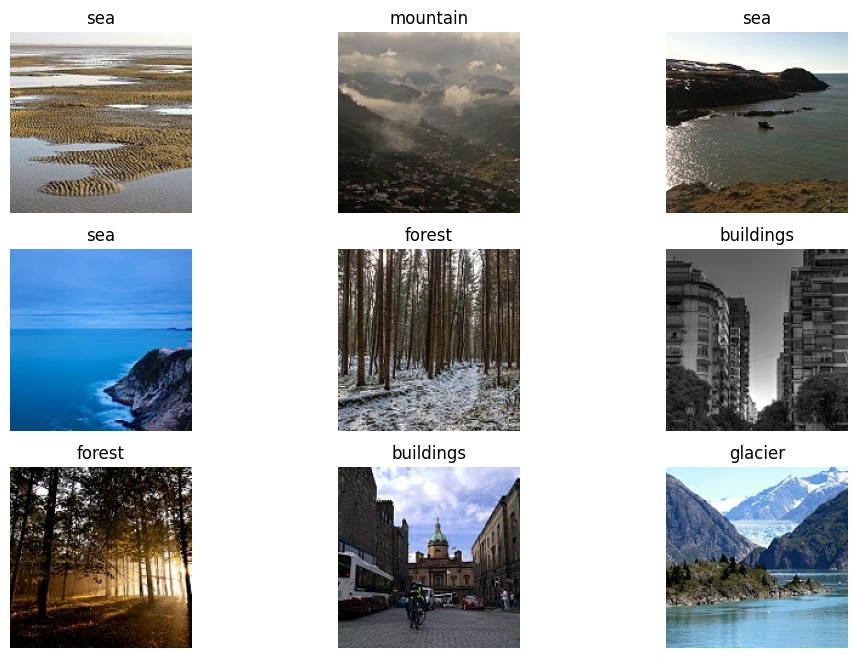

In [29]:
plt.figure(figsize=(12, 8))

for images, labels in train_ds.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i].numpy()])
        plt.axis("off")

plt.show()

In [40]:
print(train_ds.element_spec)

(TensorSpec(shape=(None, 150, 150, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))


In [42]:
images, labels = next(iter(train_ds))

image = images[7]
print(image.shape)

label = labels[7]
print(label.numpy())

(150, 150, 3)
1


# Preprocess Data (for model from scratch)

In [46]:
AUTOTUNE = tf.data.AUTOTUNE

def normalize_images(images, labels):
    images = images / 255.0
    return images, labels

val_preprocessed = val_ds.map(normalize_images)
test_preprocessed = test_ds.map(normalize_images)

In [47]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1)
])

train_preprocessed = train_ds.map(
    lambda images, labels: (data_augmentation(images, training=True) / 255.0, labels)
)

In [48]:
train_preprocessed = train_preprocessed.prefetch(AUTOTUNE)
val_preprocessed = val_preprocessed.prefetch(AUTOTUNE)
test_preprocessed = test_preprocessed.prefetch(AUTOTUNE)

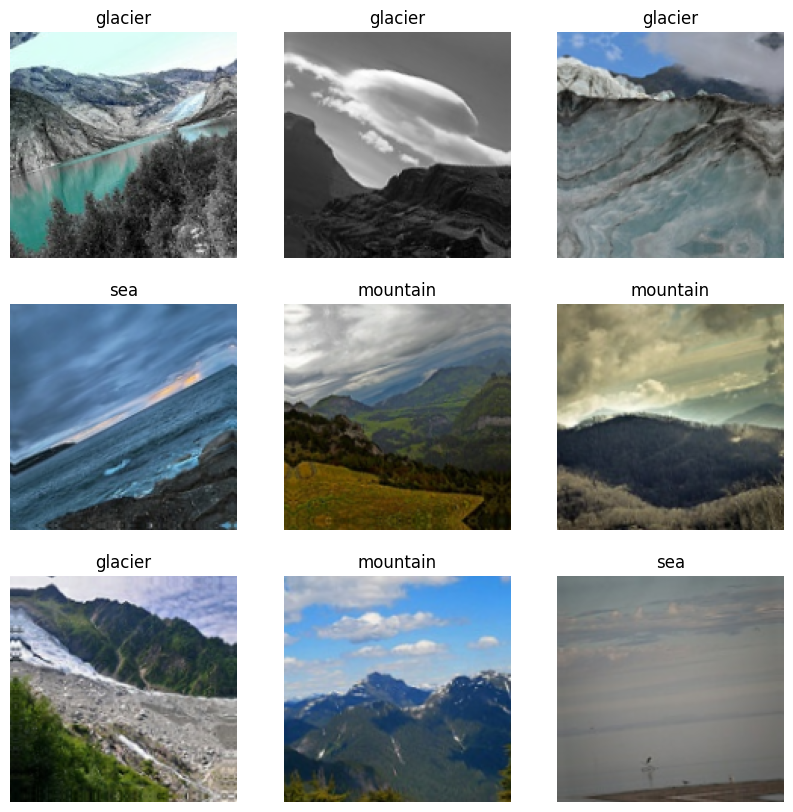

In [51]:
plt.figure(figsize=(10, 10))

for images, labels in train_preprocessed.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy())
        plt.title(class_names[labels[i].numpy()])
        plt.axis("off")

plt.show()

# Pretrained Model

In [81]:
from keras.applications.vgg16 import VGG16, preprocess_input
from keras.layers import Dense, Flatten, Dropout
from keras import models,layers

In [82]:
def vgg_preprocessing(images, labels):
    images = preprocess_input(images)
    return images, labels


train_vgg = train_ds.map(vgg_preprocessing)
val_vgg = val_ds.map(vgg_preprocessing)
test_vgg = test_ds.map(vgg_preprocessing)

In [83]:
AUTOTUNE = tf.data.AUTOTUNE

train_vgg = train_vgg.prefetch(AUTOTUNE)
val_vgg = val_vgg.prefetch(AUTOTUNE)
test_vgg = test_vgg.prefetch(AUTOTUNE)

In [84]:
vgg_base = VGG16(weights='imagenet', include_top=False, input_shape=(150, 150, 3))

In [85]:
vgg_base.summary()

Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 150, 150, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 150, 150, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 75, 75, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 75, 75, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 75, 75, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 37, 37, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 37, 37, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 37, 37, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 37, 37, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 18, 18, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 18, 18, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 18, 18, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 18, 18, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 9, 9, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 9, 9, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 9, 9, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 9, 9, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 4, 4, 512)      │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,714,688 (56.13 MB)

 Trainable params: 14,714,688 (56.13 MB)

 Non-trainable params: 0 (0.00 B)

In [86]:
for layer in vgg_base.layers:
    layer.trainable = False

In [87]:
x = vgg_base.output
x = Flatten()(x)
x = Dense(256, activation="relu")(x)
x = Dropout(0.5)(x)

output = Dense(6, activation="softmax")(x)

In [88]:
model = models.Model(
    inputs=vgg_base.input,
    outputs=output
)

In [89]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [90]:
history_1 = model.fit(
    train_vgg,
    epochs=5,
    validation_data=val_vgg,
    verbose=1
)

Epoch 1/5
351/351 ━━━━━━━━━━━━━━━━━━━━ 663s 2s/step - accuracy: 0.8407 - loss: 1.6617 - val_accuracy: 0.8999 - val_loss: 0.4451
Epoch 2/5
351/351 ━━━━━━━━━━━━━━━━━━━━ 572s 2s/step - accuracy: 0.8836 - loss: 0.4824 - val_accuracy: 0.8977 - val_loss: 0.3769
Epoch 3/5
351/351 ━━━━━━━━━━━━━━━━━━━━ 1127s 3s/step - accuracy: 0.8974 - loss: 0.3888 - val_accuracy: 0.9045 - val_loss: 0.3991
Epoch 4/5
351/351 ━━━━━━━━━━━━━━━━━━━━ 560s 2s/step - accuracy: 0.9053 - loss: 0.3743 - val_accuracy: 0.9145 - val_loss: 0.3903
Epoch 5/5
351/351 ━━━━━━━━━━━━━━━━━━━━ 753s 2s/step - accuracy: 0.9157 - loss: 0.3204 - val_accuracy: 0.9170 - val_loss: 0.3808


### Fine-Tuning

In [92]:
for layer in vgg_base.layers[:-4]:
    layer.trainable = False
for layer in vgg_base.layers[-4:]:
    layer.trainable = True

In [93]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [94]:
history_2 = model.fit(
    train_vgg,
    epochs=5,
    validation_data=val_vgg,
    verbose=1
)

Epoch 1/5
351/351 ━━━━━━━━━━━━━━━━━━━━ 653s 2s/step - accuracy: 0.9300 - loss: 0.2290 - val_accuracy: 0.9180 - val_loss: 0.3418
Epoch 2/5
351/351 ━━━━━━━━━━━━━━━━━━━━ 672s 2s/step - accuracy: 0.9428 - loss: 0.1709 - val_accuracy: 0.9234 - val_loss: 0.3535
Epoch 3/5
351/351 ━━━━━━━━━━━━━━━━━━━━ 1195s 3s/step - accuracy: 0.9517 - loss: 0.1373 - val_accuracy: 0.9269 - val_loss: 0.3628
Epoch 4/5
351/351 ━━━━━━━━━━━━━━━━━━━━ 1674s 5s/step - accuracy: 0.9595 - loss: 0.1226 - val_accuracy: 0.9273 - val_loss: 0.3468
Epoch 5/5
351/351 ━━━━━━━━━━━━━━━━━━━━ 640s 2s/step - accuracy: 0.9636 - loss: 0.1074 - val_accuracy: 0.9301 - val_loss: 0.3567


In [95]:
test_loss, test_acc = model.evaluate(test_vgg)
print(f"\n Test accuracy after fine-tuning: {test_acc:.4f}")

94/94 ━━━━━━━━━━━━━━━━━━━━ 121s 1s/step - accuracy: 0.9207 - loss: 0.3398

 Test accuracy after fine-tuning: 0.9207
